In [3]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "dice-ml"], check=True)

CompletedProcess(args=['C:\\Users\\Disha Sharma\\.conda\\envs\\analytics\\python.exe', '-m', 'pip', 'install', 'dice-ml'], returncode=0)

# Block 1 -- imports, setup, and the pickle readiness test.

In [9]:
import subprocess, sys

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", pkg], check=True)

# pip_install("dowhy")
# pip_install("dice-ml")

import pandas as pd
import numpy as np
import networkx as nx
import dowhy.gcm as gcm
import dice_ml
import matplotlib.pyplot as plt
import os
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

MODULE = "AAA"
RQ3_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\RQ3\AAA"   # adjust if your RQ3 pickle folder differs
OUTPUT_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SUCCESS_THRESHOLD = 1.5
SUCCESS_THRESHOLD_STRICT = 2.0
N_RECOURSE_QUERIES = None   # AAA: no cap, cohorts are 126 / 91
TOTAL_CFS = 3
DICE_METHOD = "random"

np.random.seed(42)

# ---- Step 0: test whether RQ3 pickles already work for counterfactuals ----

def test_pickle_invertibility(pkl_path, test_node, df_head):
    with open(pkl_path, "rb") as f:
        scm = pickle.load(f)
    try:
        _ = gcm.counterfactual_samples(
            scm, {test_node: lambda x: x},   # identity intervention, cheapest possible test
            observed_data=df_head
        )
        print(f"{pkl_path}: USABLE as-is")
        return scm, True
    except Exception as e:
        print(f"{pkl_path}: NOT usable -> {type(e).__name__}: {e}")
        return None, False

# Block 2 -- load your AAA data and run the readiness test.

In [13]:
df_raw = pd.read_csv(rf"C:\Users\Disha Sharma\Desktop\Paper_1\ModuleWise\{MODULE}.csv")

demo_cols = ['gender', 'region', 'highest_education', 'imd_band', 'age_band',
             'studied_credits', 'disability', 'num_of_prev_attempts']
ass_cols = ['ass_1_score', 'ass_2_score', 'ass_3_score', 'ass_4_score', 'ass_5_score']
click_cols = [c for c in df_raw.columns if c.startswith('clicks_')]

df_sel = df_raw[demo_cols + ass_cols + click_cols + ['final_result']].copy()

imd_mode = df_sel['imd_band'].mode()[0]
df_sel['imd_band'] = df_sel['imd_band'].fillna(imd_mode)
df_sel[ass_cols] = df_sel[ass_cols].fillna(-1)
df_sel[click_cols] = df_sel[click_cols].fillna(0)

final_result_map = {'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3}
education_map = {
    'No Formal quals': 0, 'Lower Than A Level': 1, 'A Level or Equivalent': 2,
    'HE Qualification': 3, 'Post Graduate Qualification': 4
}
age_band_map = {'0-35': 0, '35-55': 1, '55<=': 2}

df_sel['final_result'] = df_sel['final_result'].map(final_result_map)
df_sel['highest_education'] = df_sel['highest_education'].map(education_map)
df_sel['age_band'] = df_sel['age_band'].map(age_band_map)

imd_map = {
    '0-10%': 0, '10-20': 1, '20-30%': 2, '30-40%': 3, '40-50%': 4,
    '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9
}
df_sel['imd_band'] = df_raw['imd_band'].fillna(df_raw['imd_band'].mode()[0]).map(imd_map)

df_sel['gender'] = df_sel['gender'].map({'M': 0, 'F': 1})
df_sel['disability'] = df_sel['disability'].map({'N': 0, 'Y': 1})
df_sel['region'] = df_sel['region'].astype('category').cat.codes

print("Remaining NaNs:", df_sel.isnull().sum().sum())
df = df_sel

# DAG2 dataframe
nodes_dag2 = ['ass_1_score', 'ass_2_score', 'ass_3_score', 'ass_4_score', 'ass_5_score', 'final_result']
df_dag2 = df[nodes_dag2].copy()

# Combined dataframe (needs total_clicks, same construction as RQ3)
df['total_clicks'] = df[click_cols].sum(axis=1)
df['total_clicks'] = pd.qcut(df['total_clicks'], q=4, labels=False, duplicates='drop')
nodes_combined = ['gender', 'highest_education', 'studied_credits', 'age_band',
                   'total_clicks', 'ass_1_score', 'ass_2_score', 'ass_3_score',
                   'ass_4_score', 'ass_5_score', 'final_result']
df_combined = df[nodes_combined].copy()

# ---- now the readiness test ----
DAG2_PKL = os.path.join(RQ3_DIR, "AAA_scm_dag2_assessments.pkl")
COMBINED_PKL = os.path.join(RQ3_DIR, "AAA_scm_combined.pkl")

scm_dag2, dag2_usable = test_pickle_invertibility(DAG2_PKL, "ass_2_score", df_dag2.head(5))
scm_combined, combined_usable = test_pickle_invertibility(COMBINED_PKL, "ass_2_score", df_combined.head(5))

Remaining NaNs: 0
C:\Users\Disha Sharma\Desktop\Paper_1\RQ3\AAA\AAA_scm_dag2_assessments.pkl: NOT usable -> ValueError: Since no noise_data is given, this has to be estimated from the given observed_data. This can only be done with InvertibleStructuralCausalModel.
C:\Users\Disha Sharma\Desktop\Paper_1\RQ3\AAA\AAA_scm_combined.pkl: NOT usable -> ValueError: Since no noise_data is given, this has to be estimated from the given observed_data. This can only be done with InvertibleStructuralCausalModel.


In [15]:
DAG2_PKL = os.path.join(RQ3_DIR, "AAA_scm_dag2_assessments.pkl")
COMBINED_PKL = os.path.join(RQ3_DIR, "AAA_scm_combined.pkl")

# Test node: pick a non-root node for each SCM (identity intervention, cheapest test)
scm_dag2, dag2_usable = test_pickle_invertibility(DAG2_PKL, "ass_2_score", df_dag2.head(5))
scm_combined, combined_usable = test_pickle_invertibility(COMBINED_PKL, "ass_2_score", df_combined.head(5))

C:\Users\Disha Sharma\Desktop\Paper_1\RQ3\AAA\AAA_scm_dag2_assessments.pkl: NOT usable -> ValueError: Since no noise_data is given, this has to be estimated from the given observed_data. This can only be done with InvertibleStructuralCausalModel.
C:\Users\Disha Sharma\Desktop\Paper_1\RQ3\AAA\AAA_scm_combined.pkl: NOT usable -> ValueError: Since no noise_data is given, this has to be estimated from the given observed_data. This can only be done with InvertibleStructuralCausalModel.


# Block 3 -- refit all four SCMs as invertible, apply the AAA overrides, save new pickles, and check invertibility.

Test permutations of given graph: 100%|██████████| 2/2 [00:00<00:00, 185.73it/s]



===== dag1_demographics =====


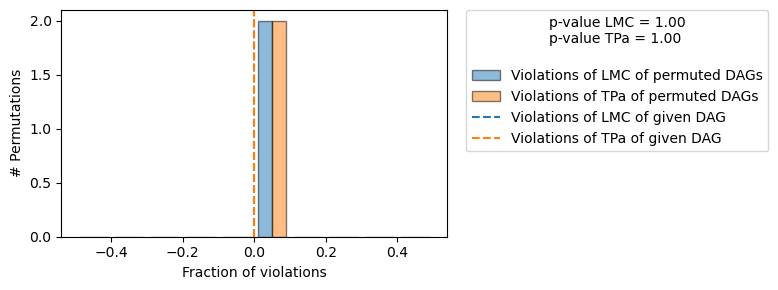

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

Test permutations of given graph: 100%|██████████| 50/50 [00:43<00:00,  1.14it/s]



===== dag2_assessments =====


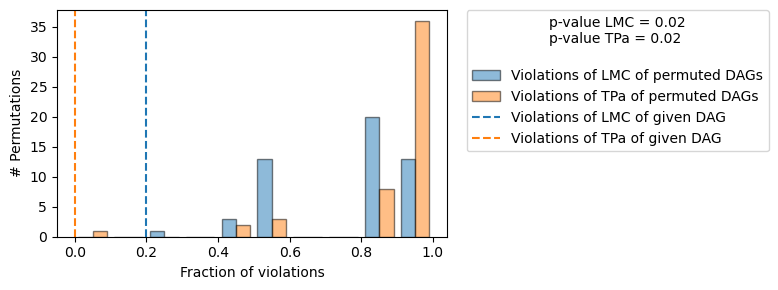

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

Test permutations of given graph: 100%|██████████| 2/2 [00:00<00:00, 208.81it/s]



===== dag3_clicks =====


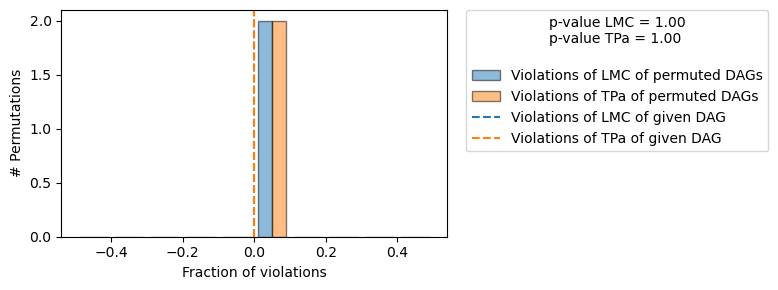

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

Test permutations of given graph: 100%|██████████| 50/50 [03:42<00:00,  4.45s/it]



===== combined =====


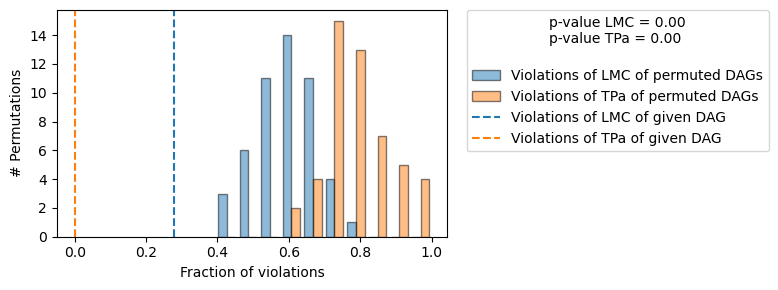

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [20]:
def fit_invertible_scm(edges, df_full, dag_name, override_fn=None):
    dag = nx.DiGraph(edges)
    assert nx.is_directed_acyclic_graph(dag), f"{dag_name} is not acyclic"
    nodes = list(dag.nodes())
    df_dag = df_full[nodes].copy()

    scm = gcm.InvertibleStructuralCausalModel(dag)
    gcm.auto.assign_causal_mechanisms(scm, df_dag)
    if override_fn is not None:
        override_fn(scm)
    gcm.fit(scm, df_dag)

    eval_result = gcm.evaluate_causal_model(scm, df_dag, compare_mechanism_baselines=True)
    print(f"\n===== {dag_name} =====")
    print(eval_result)

    pkl_path = os.path.join(OUTPUT_DIR, f"{MODULE}_rq4_scm_{dag_name}.pkl")
    with open(pkl_path, "wb") as f:
        pickle.dump(scm, f)
    print("Saved:", pkl_path)

    return scm, df_dag, eval_result


# DAG1: studied_credits -> final_result
edges_dag1 = [('studied_credits', 'final_result')]
scm_dag1, df_dag1, eval_dag1 = fit_invertible_scm(edges_dag1, df, "dag1_demographics")

# DAG2: assessment cascade
edges_dag2 = [
    ('ass_1_score', 'ass_2_score'), ('ass_1_score', 'ass_3_score'), ('ass_1_score', 'final_result'),
    ('ass_2_score', 'ass_3_score'), ('ass_2_score', 'ass_4_score'),
    ('ass_3_score', 'ass_4_score'), ('ass_3_score', 'ass_5_score'),
    ('ass_4_score', 'ass_5_score'), ('ass_4_score', 'final_result'),
    ('ass_5_score', 'final_result'),
]
scm_dag2, df_dag2, eval_dag2 = fit_invertible_scm(edges_dag2, df, "dag2_assessments")

# DAG3: clicks_resource -> final_result
edges_dag3 = [('clicks_resource', 'final_result')]
scm_dag3, df_dag3, eval_dag3 = fit_invertible_scm(edges_dag3, df, "dag3_clicks")

# Combined: same override as RQ3 (age_band -> LassoCV)
edges_combined = [
    ('gender', 'age_band'), ('highest_education', 'age_band'), ('studied_credits', 'age_band'),
    ('age_band', 'total_clicks'), ('total_clicks', 'ass_1_score'),
    ('ass_1_score', 'ass_2_score'), ('ass_1_score', 'ass_3_score'), ('ass_1_score', 'final_result'),
    ('ass_2_score', 'ass_3_score'), ('ass_2_score', 'ass_4_score'),
    ('ass_3_score', 'ass_4_score'), ('ass_3_score', 'ass_5_score'),
    ('ass_4_score', 'ass_5_score'), ('ass_4_score', 'final_result'),
    ('ass_5_score', 'final_result'),
]
def combined_override(scm):
    scm.set_causal_mechanism('age_band', gcm.AdditiveNoiseModel(gcm.ml.create_lasso_regressor()))

scm_combined, df_combined, eval_combined = fit_invertible_scm(edges_combined, df, "combined", override_fn=combined_override)

Test permutations of given graph: 100%|██████████| 50/50 [03:36<00:00,  4.33s/it]


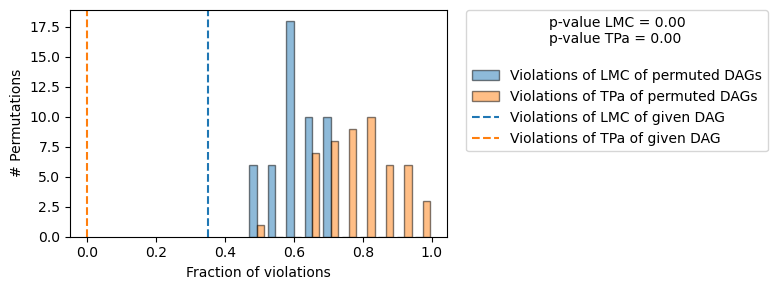

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [26]:
eval_combined = gcm.evaluate_causal_model(scm_combined, df_combined, compare_mechanism_baselines=True)
print(eval_combined)

with open(os.path.join(OUTPUT_DIR, f"{MODULE}_rq4_scm_combined.pkl"), "wb") as f:
    pickle.dump(scm_combined, f)
print("Re-saved with total_clicks override.")

# Block 5 — cohorts, helper functions, and the first counterfactual intervention on DAG2.

In [31]:
def get_cohort(df_dag, code, cap=None, seed=42):
    if isinstance(code, list):
        group = df_dag[df_dag['final_result'].isin(code)]
    else:
        group = df_dag[df_dag['final_result'] == code]
    if cap is not None and len(group) > cap:
        group = group.sample(n=cap, random_state=seed)
    return group

def run_counterfactual(scm, cohort_df, interventions):
    cf = gcm.counterfactual_samples(scm, interventions, observed_data=cohort_df.reset_index(drop=True))
    out = pd.DataFrame({
        'observed_final_result': cohort_df['final_result'].values,
        'cf_final_result': cf['final_result'].values,
    })
    out['shift'] = out['cf_final_result'] - out['observed_final_result']
    out['reaches_success_15'] = out['cf_final_result'] >= 1.5
    out['reaches_success_20'] = out['cf_final_result'] >= 2.0
    return out

def summarize_counterfactual(cf_df, label):
    return pd.Series({
        'intervention': label,
        'n': len(cf_df),
        'mean_shift': cf_df['shift'].mean(),
        'median_shift': cf_df['shift'].median(),
        'pct_reaching_success_15': cf_df['reaches_success_15'].mean() * 100,
        'pct_reaching_success_20': cf_df['reaches_success_20'].mean() * 100,
    })

# cohorts (no cap needed, AAA is small)
withdrawn_dag2 = get_cohort(df_dag2, 0)
fail_dag2 = get_cohort(df_dag2, 1)
success_dag2 = get_cohort(df_dag2, [2, 3])

print("DAG2 -- Withdrawn:", len(withdrawn_dag2), "| Fail:", len(fail_dag2), "| Success:", len(success_dag2))

# First intervention node: ass_1_score, top RQ3 contributor for Withdrawn
cf_results_dag2 = []

for node in ['ass_1_score', 'ass_2_score', 'ass_4_score', 'ass_5_score']:
    target_val = success_dag2[node].median()
    for cohort_name, cohort_df in [('Withdrawn', withdrawn_dag2), ('Fail', fail_dag2)]:
        # style 1: raise to Success median, never lower (max with current value)
        cf_median = run_counterfactual(
            scm_dag2, cohort_df,
            {node: lambda x, t=target_val: np.maximum(x, t)}
        )
        s = summarize_counterfactual(cf_median, f"{node}_to_success_median")
        s['node'] = node; s['cohort'] = cohort_name
        cf_results_dag2.append(s)

        # style 2: +10 point step, bounded at 100 (non-submission -1 floored to 0 first)
        cf_step = run_counterfactual(
            scm_dag2, cohort_df,
            {node: lambda x: np.clip(np.maximum(x, 0) + 10, 0, 100)}
        )
        s2 = summarize_counterfactual(cf_step, f"{node}_plus10")
        s2['node'] = node; s2['cohort'] = cohort_name
        cf_results_dag2.append(s2)

cf_summary_dag2 = pd.DataFrame(cf_results_dag2)
print(cf_summary_dag2)
cf_summary_dag2.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG2_cf_summary.csv"), index=False)

DAG2 -- Withdrawn: 126 | Fail: 91 | Success: 531
                     intervention    n  mean_shift  median_shift  \
0   ass_1_score_to_success_median  126    0.753968           0.0   
1              ass_1_score_plus10  126    0.674603           1.0   
2   ass_1_score_to_success_median   91    0.604396           0.0   
3              ass_1_score_plus10   91    0.505495           1.0   
4   ass_2_score_to_success_median  126    0.880952           1.0   
5              ass_2_score_plus10  126    0.587302           1.0   
6   ass_2_score_to_success_median   91    0.659341           1.0   
7              ass_2_score_plus10   91    0.384615           0.0   
8   ass_4_score_to_success_median  126    1.785714           2.0   
9              ass_4_score_plus10  126    0.896825           1.0   
10  ass_4_score_to_success_median   91    1.142857           1.0   
11             ass_4_score_plus10   91    0.582418           1.0   
12  ass_5_score_to_success_median  126    1.119048           1.0   

In [33]:
print(cf_median['cf_final_result'].describe())
print(cf_median['cf_final_result'].between(1.5, 2.0, inclusive='left').sum())

count    91.000000
mean      1.703297
std       0.875525
min       0.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       3.000000
Name: cf_final_result, dtype: float64
0


In [35]:
# DAG3 cohorts
withdrawn_dag3 = get_cohort(df_dag3, 0)
fail_dag3 = get_cohort(df_dag3, 1)
success_dag3 = get_cohort(df_dag3, [2, 3])

target_resource = success_dag3['clicks_resource'].median()
cf_results_dag3 = []
for cohort_name, cohort_df in [('Withdrawn', withdrawn_dag3), ('Fail', fail_dag3)]:
    cf_median = run_counterfactual(scm_dag3, cohort_df,
        {'clicks_resource': lambda x, t=target_resource: np.maximum(x, t)})
    s = summarize_counterfactual(cf_median, "clicks_resource_to_success_median")
    s['cohort'] = cohort_name
    cf_results_dag3.append(s)

cf_summary_dag3 = pd.DataFrame(cf_results_dag3)
print(cf_summary_dag3)
cf_summary_dag3.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG3_cf_summary.csv"), index=False)

# Combined: fairness counterfactuals on immutable nodes with a path to final_result
withdrawn_combined = get_cohort(df_combined, 0)
fail_combined = get_cohort(df_combined, 1)

fairness_results = []
for node in ['gender', 'highest_education', 'age_band', 'studied_credits']:
    ref_val = df_combined[node].max()  # best observed category/value as reference
    for cohort_name, cohort_df in [('Withdrawn', withdrawn_combined), ('Fail', fail_combined)]:
        cf_fair = run_counterfactual(scm_combined, cohort_df, {node: lambda x, v=ref_val: v})
        s = summarize_counterfactual(cf_fair, f"{node}_to_max")
        s['node'] = node; s['cohort'] = cohort_name
        fairness_results.append(s)

fairness_summary = pd.DataFrame(fairness_results)
print(fairness_summary)
fairness_summary.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_fairness_summary.csv"), index=False)

                        intervention    n  mean_shift  median_shift  \
0  clicks_resource_to_success_median  126    0.730159           1.0   
1  clicks_resource_to_success_median   91    0.538462           0.0   

   pct_reaching_success_15  pct_reaching_success_20     cohort  
0                17.460317                17.460317  Withdrawn  
1                43.956044                43.956044       Fail  
               intervention    n  mean_shift  median_shift  \
0             gender_to_max  126    0.000000           0.0   
1             gender_to_max   91    0.000000           0.0   
2  highest_education_to_max  126    0.000000           0.0   
3  highest_education_to_max   91    0.000000           0.0   
4           age_band_to_max  126    0.476190           0.0   
5           age_band_to_max   91    0.527473           1.0   
6    studied_credits_to_max  126    0.000000           0.0   
7    studied_credits_to_max   91    0.000000           0.0   

   pct_reaching_success_15  pct_

In [37]:
cf_check = run_counterfactual(scm_combined, withdrawn_combined,
    {'gender': lambda x: 1 - x})
print(cf_check['shift'].abs().max())
print(cf_check['shift'].value_counts())

0
shift
0    126
Name: count, dtype: int64


# Block 6 — train the DAG2 recourse classifier and check AUC before generating any recourse.

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

feat_cols_dag2 = ['ass_1_score', 'ass_2_score', 'ass_3_score', 'ass_4_score', 'ass_5_score']
data_dag2 = df_dag2.copy()
data_dag2['success'] = (data_dag2['final_result'] >= 2).astype(int)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    data_dag2[feat_cols_dag2], data_dag2['success'],
    test_size=0.2, random_state=42, stratify=data_dag2['success'])

clf_dag2 = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train2, y_train2)
auc_dag2 = roc_auc_score(y_test2, clf_dag2.predict_proba(X_test2)[:, 1])
print("DAG2 classifier AUC:", auc_dag2)
print("Train class balance:", y_train2.value_counts(normalize=True).to_dict())
print("Test class balance:", y_test2.value_counts(normalize=True).to_dict())

DAG2 classifier AUC: 0.9338550600343053
Train class balance: {1: 0.7107023411371237, 0: 0.28929765886287623}
Test class balance: {1: 0.7066666666666667, 0: 0.29333333333333333}


# Block 7 — generate DiCE recourse candidates for DAG2 (Withdrawn and Fail cohorts).

In [43]:
train_df2 = X_train2.copy()
train_df2['success'] = y_train2.values

d2 = dice_ml.Data(dataframe=train_df2, continuous_features=feat_cols_dag2, outcome_name='success')
m2 = dice_ml.Model(model=clf_dag2, backend='sklearn')
exp2 = dice_ml.Dice(d2, m2, method=DICE_METHOD)

permitted_range2 = {c: [train_df2[c].min(), train_df2[c].max()] for c in feat_cols_dag2}
print("Permitted ranges:", permitted_range2)

def generate_recourse(exp, df_dag, feat_cols, cohort_code, cap, total_cfs, permitted_range):
    queries = get_cohort(df_dag, cohort_code, cap=cap)[feat_cols]
    cfs = exp.generate_counterfactuals(
        queries, total_CFs=total_cfs, desired_class=1,
        features_to_vary=feat_cols, permitted_range=permitted_range
    )
    return queries, cfs

queries_w2, cfs_w2 = generate_recourse(exp2, df_dag2, feat_cols_dag2, 0, N_RECOURSE_QUERIES, TOTAL_CFS, permitted_range2)
queries_f2, cfs_f2 = generate_recourse(exp2, df_dag2, feat_cols_dag2, 1, N_RECOURSE_QUERIES, TOTAL_CFS, permitted_range2)

print("Withdrawn queries:", len(queries_w2), "| Fail queries:", len(queries_f2))

Permitted ranges: {'ass_1_score': [-1.0, 94.0], 'ass_2_score': [-1.0, 95.0], 'ass_3_score': [-1.0, 94.0], 'ass_4_score': [-1.0, 94.0], 'ass_5_score': [-1.0, 98.0]}


100%|██████████| 91/91 [01:33<00:00,  1.03s/it]

Withdrawn queries: 126 | Fail queries: 91


# Block 8 — extract DiCE candidates, identify changed features, and push each through the SCM.

In [46]:
def extract_candidates(cfs, queries, feat_cols):
    """Flatten DiCE's per-student candidate lists into one dataframe."""
    rows = []
    for i, example in enumerate(cfs.cf_examples_list):
        orig_row = queries.iloc[i]
        cf_df = example.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue  # DiCE failed to find a valid candidate for this student
        for j, cf_row in cf_df.iterrows():
            changed = [c for c in feat_cols if not np.isclose(cf_row[c], orig_row[c])]
            rows.append({
                'student_idx': queries.index[i],
                'candidate_idx': j,
                'orig_row': orig_row,
                'cf_row': cf_row[feat_cols],
                'changed_features': changed,
                'dice_validity': cf_row['success'] if 'success' in cf_row else 1,  # DiCE only returns flipped candidates
            })
    return rows

candidates_w2 = extract_candidates(cfs_w2, queries_w2, feat_cols_dag2)
candidates_f2 = extract_candidates(cfs_f2, queries_f2, feat_cols_dag2)

print("Withdrawn candidates extracted:", len(candidates_w2), "/ expected", len(queries_w2) * TOTAL_CFS)
print("Fail candidates extracted:", len(candidates_f2), "/ expected", len(queries_f2) * TOTAL_CFS)

# sanity check one example
print("\nExample Withdrawn candidate:")
print("Original:", candidates_w2[0]['orig_row'].to_dict())
print("Candidate:", candidates_w2[0]['cf_row'].to_dict())
print("Changed:", candidates_w2[0]['changed_features'])

Withdrawn candidates extracted: 378 / expected 378
Fail candidates extracted: 273 / expected 273

Example Withdrawn candidate:
Original: {'ass_1_score': -1.0, 'ass_2_score': -1.0, 'ass_3_score': -1.0, 'ass_4_score': -1.0, 'ass_5_score': -1.0}
Candidate: {'ass_1_score': -1.0, 'ass_2_score': -1.0, 'ass_3_score': 80.4, 'ass_4_score': -1.0, 'ass_5_score': 58.0}
Changed: ['ass_3_score', 'ass_5_score']


# Block 9 — causal verification through the SCM (hard and propagated modes)

In [49]:
def causal_check(scm, student_row, cf_row, changed, mode="hard"):
    nodes = [n for n in changed if n in scm.graph.nodes]
    if mode == "propagated":
        g = scm.graph
        nodes = [n for n in nodes if not any(a in nodes for a in nx.ancestors(g, n))]
    if len(nodes) == 0:
        return float(student_row['final_result']) if 'final_result' in student_row else None
    interventions = {n: (lambda x, v=cf_row[n]: v) for n in nodes}
    student_full = student_row.to_frame().T.reset_index(drop=True)
    out = gcm.counterfactual_samples(scm, interventions, observed_data=student_full)
    return float(out['final_result'].iloc[0])

def verify_candidates(candidates, scm, df_dag, feat_cols):
    results = []
    for c in candidates:
        orig_full = df_dag.loc[c['student_idx']]
        cf_hard = causal_check(scm, orig_full, c['cf_row'], c['changed_features'], mode="hard")
        cf_prop = causal_check(scm, orig_full, c['cf_row'], c['changed_features'], mode="propagated")
        results.append({
            'student_idx': c['student_idx'],
            'candidate_idx': c['candidate_idx'],
            'changed_features': ','.join(c['changed_features']),
            'n_changed': len(c['changed_features']),
            'cf_final_result_hard': cf_hard,
            'cf_final_result_propagated': cf_prop,
            'causal_valid_hard_15': cf_hard >= 1.5,
            'causal_valid_hard_20': cf_hard >= 2.0,
            'causal_valid_prop_15': cf_prop >= 1.5,
            'causal_valid_prop_20': cf_prop >= 2.0,
        })
    return pd.DataFrame(results)

verified_w2 = verify_candidates(candidates_w2, scm_dag2, df_dag2, feat_cols_dag2)
verified_f2 = verify_candidates(candidates_f2, scm_dag2, df_dag2, feat_cols_dag2)

verified_w2.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG2_Withdrawn_recourse.csv"), index=False)
verified_f2.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG2_Fail_recourse.csv"), index=False)

print("Withdrawn:")
print(verified_w2[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())
print("\nFail:")
print(verified_f2[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())

Withdrawn:
causal_valid_hard_15    0.486772
causal_valid_prop_15    0.216931
dtype: float64

Fail:
causal_valid_hard_15    0.560440
causal_valid_prop_15    0.600733
dtype: float64


In [51]:
# flag students where propagated causal validity differs from hard
diff_cases = verified_f2[verified_f2['causal_valid_hard_15'] != verified_f2['causal_valid_prop_15']]
print(len(diff_cases))
print(diff_cases[['n_changed', 'changed_features', 'cf_final_result_hard', 'cf_final_result_propagated']].head(10))

# also check: does this happen more when 2+ features changed?
print(verified_f2.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())
print(verified_w2.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())

45
    n_changed         changed_features  cf_final_result_hard  \
0           2  ass_4_score,ass_5_score                   2.0   
5           2  ass_3_score,ass_4_score                   2.0   
6           2  ass_3_score,ass_5_score                   2.0   
7           2  ass_2_score,ass_5_score                   2.0   
8           2  ass_1_score,ass_5_score                   2.0   
52          2  ass_3_score,ass_5_score                   1.0   
53          2  ass_3_score,ass_5_score                   1.0   
54          2  ass_2_score,ass_5_score                   2.0   
66          2  ass_2_score,ass_4_score                   2.0   
67          2  ass_1_score,ass_4_score                   2.0   

    cf_final_result_propagated  
0                          1.0  
5                          1.0  
6                          1.0  
7                         -1.0  
8                          1.0  
52                         2.0  
53                         2.0  
54                         1

In [53]:
print("Fail n_changed counts and rates:")
print(verified_f2.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].agg(['mean', 'count']))

print("\nWithdrawn n_changed counts and rates:")
print(verified_w2.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].agg(['mean', 'count']))

Fail n_changed counts and rates:
          causal_valid_hard_15       causal_valid_prop_15      
                          mean count                 mean count
n_changed                                                      
1                     0.414634    82             0.414634    82
2                     0.623037   191             0.680628   191

Withdrawn n_changed counts and rates:
          causal_valid_hard_15       causal_valid_prop_15      
                          mean count                 mean count
n_changed                                                      
1                     0.488372    43             0.488372    43
2                     0.486567   335             0.182090   335


# Block 10 — DAG3 classifier and recourse

In [56]:
click_cols_dag3 = click_cols  # all 9 AAA click types, from your original preprocessing
df_clicks = df[click_cols_dag3 + ['final_result']].copy()
data_dag3 = df_clicks.copy()
data_dag3['success'] = (data_dag3['final_result'] >= 2).astype(int)

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    data_dag3[click_cols_dag3], data_dag3['success'],
    test_size=0.2, random_state=42, stratify=data_dag3['success'])

clf_dag3 = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train3, y_train3)
auc_dag3 = roc_auc_score(y_test3, clf_dag3.predict_proba(X_test3)[:, 1])
print("DAG3 (all clicks) classifier AUC:", auc_dag3)

train_df3 = X_train3.copy()
train_df3['success'] = y_train3.values

# 95th percentile cap per click type, since raw click counts are heavy-tailed
permitted_range3 = {
    c: [train_df3[c].min(), train_df3[c].quantile(0.95)] for c in click_cols_dag3
}
print("Permitted ranges (DAG3):", permitted_range3)

d3 = dice_ml.Data(dataframe=train_df3, continuous_features=click_cols_dag3, outcome_name='success')
m3 = dice_ml.Model(model=clf_dag3, backend='sklearn')
exp3 = dice_ml.Dice(d3, m3, method=DICE_METHOD)

def get_cohort_clicks(df_in, code, cap=None, seed=42):
    if isinstance(code, list):
        group = df_in[df_in['final_result'].isin(code)]
    else:
        group = df_in[df_in['final_result'] == code]
    if cap is not None and len(group) > cap:
        group = group.sample(n=cap, random_state=seed)
    return group

queries_w3 = get_cohort_clicks(df_clicks, 0, N_RECOURSE_QUERIES)[click_cols_dag3]
queries_f3 = get_cohort_clicks(df_clicks, 1, N_RECOURSE_QUERIES)[click_cols_dag3]

cfs_w3 = exp3.generate_counterfactuals(queries_w3, total_CFs=TOTAL_CFS, desired_class=1,
                                        features_to_vary=click_cols_dag3, permitted_range=permitted_range3)
cfs_f3 = exp3.generate_counterfactuals(queries_f3, total_CFs=TOTAL_CFS, desired_class=1,
                                        features_to_vary=click_cols_dag3, permitted_range=permitted_range3)

print("Withdrawn queries:", len(queries_w3), "| Fail queries:", len(queries_f3))

DAG3 (all clicks) classifier AUC: 0.8113207547169812
Permitted ranges (DAG3): {'clicks_dataplus': [0.0, np.float64(20.0)], 'clicks_forumng': [0.0, np.float64(2259.1499999999983)], 'clicks_glossary': [0.0, np.float64(4.0)], 'clicks_homepage': [0.0, np.float64(1065.8999999999999)], 'clicks_oucollaborate': [0.0, np.float64(3.0)], 'clicks_oucontent': [0.0, np.float64(1899.0999999999997)], 'clicks_resource': [0.0, np.float64(56.44999999999993)], 'clicks_subpage': [0.0, np.float64(250.29999999999995)], 'clicks_url': [0.0, np.float64(139.29999999999995)]}


100%|██████████| 91/91 [02:12<00:00,  1.45s/it]

Withdrawn queries: 126 | Fail queries: 91


In [58]:
candidates_w3 = extract_candidates(cfs_w3, queries_w3, click_cols_dag3)
candidates_f3 = extract_candidates(cfs_f3, queries_f3, click_cols_dag3)

print("Withdrawn candidates:", len(candidates_w3), "/ expected", len(queries_w3) * TOTAL_CFS)
print("Fail candidates:", len(candidates_f3), "/ expected", len(queries_f3) * TOTAL_CFS)

verified_w3 = verify_candidates(candidates_w3, scm_dag3, df_clicks, click_cols_dag3)
verified_f3 = verify_candidates(candidates_f3, scm_dag3, df_clicks, click_cols_dag3)

verified_w3.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG3_Withdrawn_recourse.csv"), index=False)
verified_f3.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_DAG3_Fail_recourse.csv"), index=False)

print("\nWithdrawn causal validity:")
print(verified_w3[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())
print("\nFail causal validity:")
print(verified_f3[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())

# the headline Option B number: how often did DiCE even TOUCH clicks_resource at all
touched_resource_w = sum('clicks_resource' in c['changed_features'] for c in candidates_w3)
touched_resource_f = sum('clicks_resource' in c['changed_features'] for c in candidates_f3)
print(f"\nWithdrawn candidates touching clicks_resource: {touched_resource_w}/{len(candidates_w3)}")
print(f"Fail candidates touching clicks_resource: {touched_resource_f}/{len(candidates_f3)}")

# DiCE validity (did it flip the classifier) vs causal validity, for the headline gap
print(f"\nDiCE validity: 100% by construction (DiCE only returns flipped candidates)")

Withdrawn candidates: 378 / expected 378
Fail candidates: 273 / expected 273

Withdrawn causal validity:
causal_valid_hard_15    0.174603
causal_valid_prop_15    0.174603
dtype: float64

Fail causal validity:
causal_valid_hard_15    0.197802
causal_valid_prop_15    0.197802
dtype: float64

Withdrawn candidates touching clicks_resource: 158/378
Fail candidates touching clicks_resource: 85/273

DiCE validity: 100% by construction (DiCE only returns flipped candidates)


In [60]:
feat_cols_combined = ['total_clicks', 'ass_1_score', 'ass_2_score', 'ass_3_score', 'ass_4_score', 'ass_5_score']
data_combined = df_combined.copy()
data_combined['success'] = (data_combined['final_result'] >= 2).astype(int)

X_trainC, X_testC, y_trainC, y_testC = train_test_split(
    data_combined[feat_cols_combined], data_combined['success'],
    test_size=0.2, random_state=42, stratify=data_combined['success'])

clf_combined = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_trainC, y_trainC)
auc_combined = roc_auc_score(y_testC, clf_combined.predict_proba(X_testC)[:, 1])
print("Combined classifier AUC:", auc_combined)

train_dfC = X_trainC.copy()
train_dfC['success'] = y_trainC.values

permitted_rangeC = {c: [train_dfC[c].min(), train_dfC[c].max()] for c in feat_cols_combined}
print("Permitted ranges:", permitted_rangeC)

dC = dice_ml.Data(dataframe=train_dfC, continuous_features=feat_cols_combined, outcome_name='success')
mC = dice_ml.Model(model=clf_combined, backend='sklearn')
expC = dice_ml.Dice(dC, mC, method=DICE_METHOD)

queries_wC = get_cohort(df_combined, 0, N_RECOURSE_QUERIES)[feat_cols_combined]
queries_fC = get_cohort(df_combined, 1, N_RECOURSE_QUERIES)[feat_cols_combined]

cfs_wC = expC.generate_counterfactuals(queries_wC, total_CFs=TOTAL_CFS, desired_class=1,
                                        features_to_vary=feat_cols_combined, permitted_range=permitted_rangeC)
cfs_fC = expC.generate_counterfactuals(queries_fC, total_CFs=TOTAL_CFS, desired_class=1,
                                        features_to_vary=feat_cols_combined, permitted_range=permitted_rangeC)

print("Withdrawn queries:", len(queries_wC), "| Fail queries:", len(queries_fC))

Combined classifier AUC: 0.9341766723842195
Permitted ranges: {'total_clicks': [0, 3], 'ass_1_score': [-1.0, 94.0], 'ass_2_score': [-1.0, 95.0], 'ass_3_score': [-1.0, 94.0], 'ass_4_score': [-1.0, 94.0], 'ass_5_score': [-1.0, 98.0]}


100%|██████████| 91/91 [01:29<00:00,  1.02it/s]

Withdrawn queries: 126 | Fail queries: 91


In [62]:
candidates_wC = extract_candidates(cfs_wC, queries_wC, feat_cols_combined)
candidates_fC = extract_candidates(cfs_fC, queries_fC, feat_cols_combined)

print("Withdrawn candidates:", len(candidates_wC), "/ expected", len(queries_wC) * TOTAL_CFS)
print("Fail candidates:", len(candidates_fC), "/ expected", len(queries_fC) * TOTAL_CFS)

verified_wC = verify_candidates(candidates_wC, scm_combined, df_combined, feat_cols_combined)
verified_fC = verify_candidates(candidates_fC, scm_combined, df_combined, feat_cols_combined)

verified_wC.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_Withdrawn_recourse.csv"), index=False)
verified_fC.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_Fail_recourse.csv"), index=False)

print("\nWithdrawn causal validity:")
print(verified_wC[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())
print("\nFail causal validity:")
print(verified_fC[['causal_valid_hard_15', 'causal_valid_prop_15']].mean())

# breakdown by n_changed, since AAA DAG2 showed this matters a lot
print("\nWithdrawn by n_changed:")
print(verified_wC.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].agg(['mean', 'count']))
print("\nFail by n_changed:")
print(verified_fC.groupby('n_changed')[['causal_valid_hard_15', 'causal_valid_prop_15']].agg(['mean', 'count']))

# how often does DiCE touch total_clicks specifically, the key engagement lever
touched_tc_w = sum('total_clicks' in c['changed_features'] for c in candidates_wC)
touched_tc_f = sum('total_clicks' in c['changed_features'] for c in candidates_fC)
print(f"\nWithdrawn candidates touching total_clicks: {touched_tc_w}/{len(candidates_wC)}")
print(f"Fail candidates touching total_clicks: {touched_tc_f}/{len(candidates_fC)}")

Withdrawn candidates: 378 / expected 378
Fail candidates: 273 / expected 273

Withdrawn causal validity:
causal_valid_hard_15    0.492063
causal_valid_prop_15    0.264550
dtype: float64

Fail causal validity:
causal_valid_hard_15    0.505495
causal_valid_prop_15    0.564103
dtype: float64

Withdrawn by n_changed:
          causal_valid_hard_15       causal_valid_prop_15      
                          mean count                 mean count
n_changed                                                      
1                     0.680851    47             0.680851    47
2                     0.466463   328             0.207317   328
3                     0.333333     3             0.000000     3

Fail by n_changed:
          causal_valid_hard_15       causal_valid_prop_15      
                          mean count                 mean count
n_changed                                                      
1                     0.342857    70             0.342857    70
2                     0.5

# recourse metrics (2d) and visualizations for all three recourse pipelines (DAG2, DAG3, Combined)


===== DAG2_Assessments metrics =====
      cohort  n_candidates  validity  causal_validity_hard  \
0  Withdrawn           378     100.0             48.677249   
1       Fail           273     100.0             56.043956   

   causal_validity_prop  validity_gap_hard  validity_gap_prop  proximity  \
0             21.693122          51.322751          78.306878   0.257562   
1             60.073260          43.956044          39.926740   0.181305   

   sparsity  diversity  
0  1.886243   0.126851  
1  1.699634   0.126180  


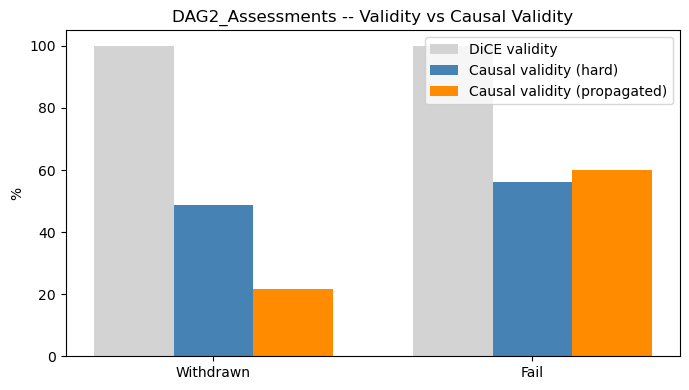

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_DAG2_Assessments_validity_bars.png


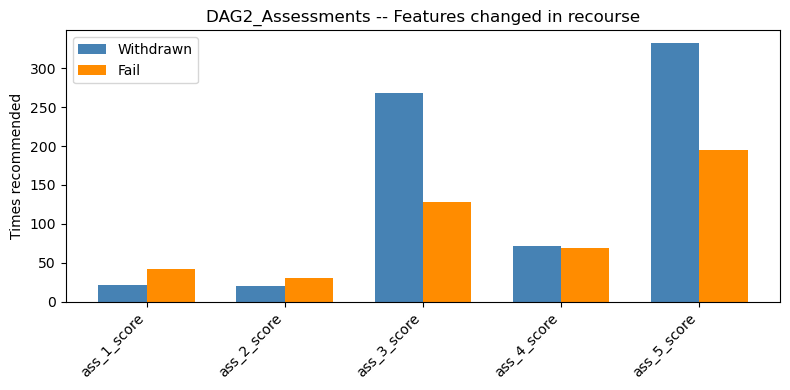

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_DAG2_Assessments_feature_freq.png

===== DAG3_Clicks metrics =====
      cohort  n_candidates  validity  causal_validity_hard  \
0  Withdrawn           378     100.0             17.460317   
1       Fail           273     100.0             19.780220   

   causal_validity_prop  validity_gap_hard  validity_gap_prop  proximity  \
0             17.460317          82.539683          82.539683   0.100055   
1             19.780220          80.219780          80.219780   0.094455   

   sparsity  diversity  
0  1.751323   0.132149  
1  1.732601   0.136664  


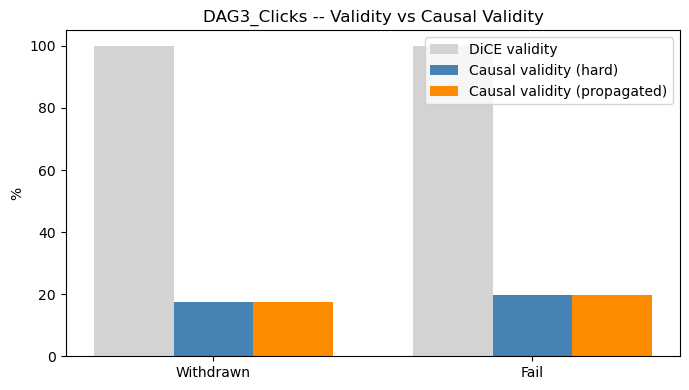

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_DAG3_Clicks_validity_bars.png


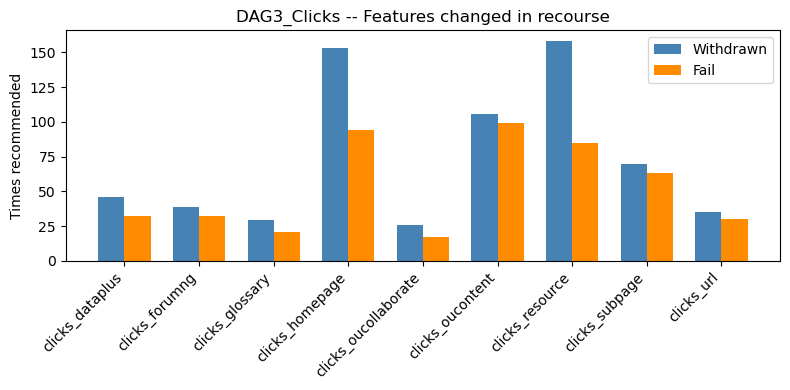

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_DAG3_Clicks_feature_freq.png

===== Combined metrics =====
      cohort  n_candidates  validity  causal_validity_hard  \
0  Withdrawn           378     100.0             49.206349   
1       Fail           273     100.0             50.549451   

   causal_validity_prop  validity_gap_hard  validity_gap_prop  proximity  \
0             26.455026          50.793651          73.544974   0.219941   
1             56.410256          49.450549          43.589744   0.162017   

   sparsity  diversity  
0  1.883598   0.100052  
1  1.743590   0.116551  


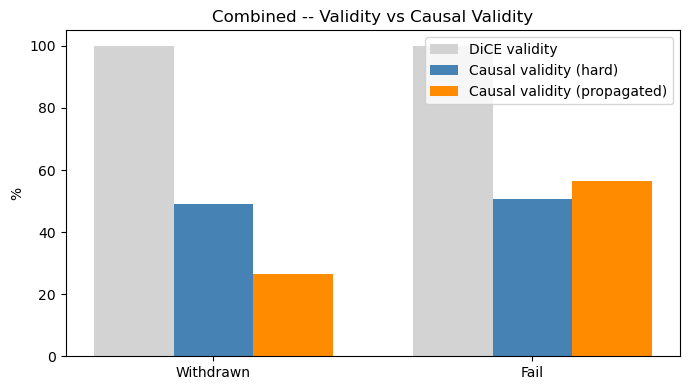

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_validity_bars.png


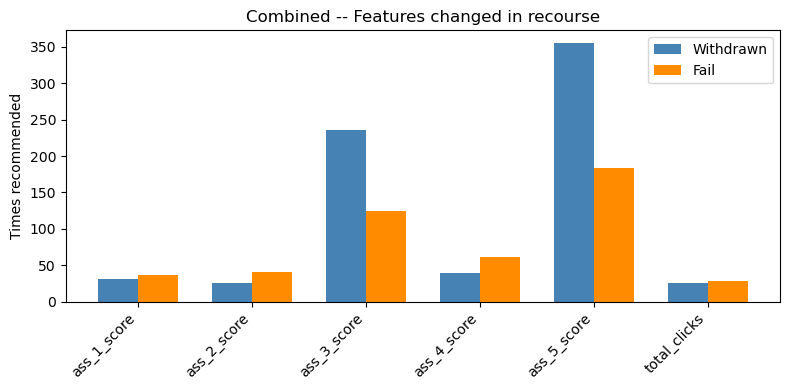

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_feature_freq.png


In [65]:
def compute_proximity(candidates, feat_cols, ranges):
    vals = []
    for c in candidates:
        orig, cf = c['orig_row'], c['cf_row']
        dists = [abs(cf[f] - orig[f]) / max(ranges[f][1] - ranges[f][0], 1e-9) for f in feat_cols]
        vals.append(np.mean(dists))
    return np.mean(vals)

def compute_diversity(candidates, feat_cols, ranges):
    from collections import defaultdict
    by_student = defaultdict(list)
    for c in candidates:
        by_student[c['student_idx']].append(c['cf_row'])
    dists = []
    for student_idx, cf_list in by_student.items():
        if len(cf_list) < 2:
            continue
        for i in range(len(cf_list)):
            for j in range(i + 1, len(cf_list)):
                d = np.mean([abs(cf_list[i][f] - cf_list[j][f]) / max(ranges[f][1] - ranges[f][0], 1e-9) for f in feat_cols])
                dists.append(d)
    return np.mean(dists) if dists else np.nan

def feature_change_freq(candidates, feat_cols):
    counts = {f: 0 for f in feat_cols}
    for c in candidates:
        for f in c['changed_features']:
            counts[f] += 1
    return pd.Series(counts).sort_values(ascending=False)

def build_metrics_table(candidates, verified, feat_cols, ranges, cohort_label):
    return pd.Series({
        'cohort': cohort_label,
        'n_candidates': len(candidates),
        'validity': 100.0,  # DiCE-only candidates, by construction
        'causal_validity_hard': verified['causal_valid_hard_15'].mean() * 100,
        'causal_validity_prop': verified['causal_valid_prop_15'].mean() * 100,
        'validity_gap_hard': 100.0 - verified['causal_valid_hard_15'].mean() * 100,
        'validity_gap_prop': 100.0 - verified['causal_valid_prop_15'].mean() * 100,
        'proximity': compute_proximity(candidates, feat_cols, ranges),
        'sparsity': verified['n_changed'].mean(),
        'diversity': compute_diversity(candidates, feat_cols, ranges),
    })

def plot_validity_bars(metrics_df, dag_name):
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(metrics_df))
    width = 0.25
    ax.bar(x - width, metrics_df['validity'], width, label='DiCE validity', color='lightgray')
    ax.bar(x, metrics_df['causal_validity_hard'], width, label='Causal validity (hard)', color='steelblue')
    ax.bar(x + width, metrics_df['causal_validity_prop'], width, label='Causal validity (propagated)', color='darkorange')
    ax.set_xticks(x); ax.set_xticklabels(metrics_df['cohort'])
    ax.set_ylabel('%'); ax.set_title(f'{dag_name} -- Validity vs Causal Validity')
    ax.legend(); plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_{dag_name}_validity_bars.png")
    plt.savefig(path); plt.show()
    print("Saved:", path)

def plot_feature_freq(freq_w, freq_f, dag_name):
    fig, ax = plt.subplots(figsize=(8, 4))
    all_feats = sorted(set(freq_w.index) | set(freq_f.index))
    x = np.arange(len(all_feats))
    width = 0.35
    ax.bar(x - width/2, [freq_w.get(f, 0) for f in all_feats], width, label='Withdrawn', color='steelblue')
    ax.bar(x + width/2, [freq_f.get(f, 0) for f in all_feats], width, label='Fail', color='darkorange')
    ax.set_xticks(x); ax.set_xticklabels(all_feats, rotation=45, ha='right')
    ax.set_ylabel('Times recommended'); ax.set_title(f'{dag_name} -- Features changed in recourse')
    ax.legend(); plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_{dag_name}_feature_freq.png")
    plt.savefig(path); plt.show()
    print("Saved:", path)

# ---- run for all three pipelines ----
pipelines = {
    'DAG2_Assessments': (candidates_w2, candidates_f2, verified_w2, verified_f2, feat_cols_dag2, permitted_range2),
    'DAG3_Clicks':       (candidates_w3, candidates_f3, verified_w3, verified_f3, click_cols_dag3, permitted_range3),
    'Combined':          (candidates_wC, candidates_fC, verified_wC, verified_fC, feat_cols_combined, permitted_rangeC),
}

all_metrics = []
for dag_name, (cw, cf, vw, vf, feats, ranges) in pipelines.items():
    m_w = build_metrics_table(cw, vw, feats, ranges, 'Withdrawn')
    m_f = build_metrics_table(cf, vf, feats, ranges, 'Fail')
    metrics_df = pd.DataFrame([m_w, m_f])
    metrics_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_{dag_name}_recourse_metrics.csv"), index=False)
    print(f"\n===== {dag_name} metrics =====")
    print(metrics_df)
    all_metrics.append(metrics_df.assign(dag=dag_name))

    plot_validity_bars(metrics_df, dag_name)

    freq_w = feature_change_freq(cw, feats)
    freq_f = feature_change_freq(cf, feats)
    plot_feature_freq(freq_w, freq_f, dag_name)

all_metrics_df = pd.concat(all_metrics, ignore_index=True)
all_metrics_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_ALL_recourse_metrics.csv"), index=False)

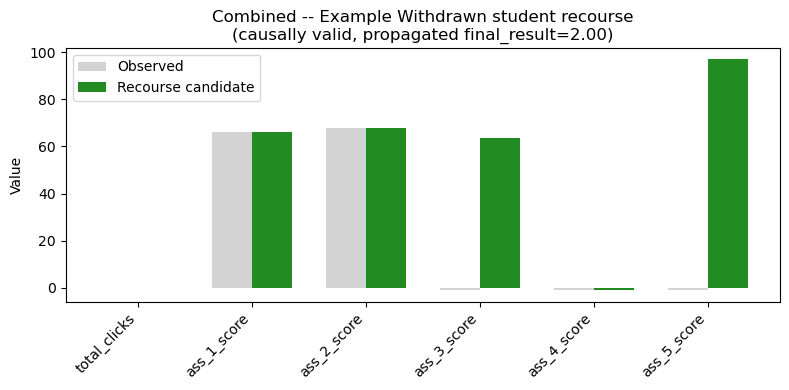

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_Withdrawn_example_recourse.png
Changed features: ['ass_3_score', 'ass_5_score']


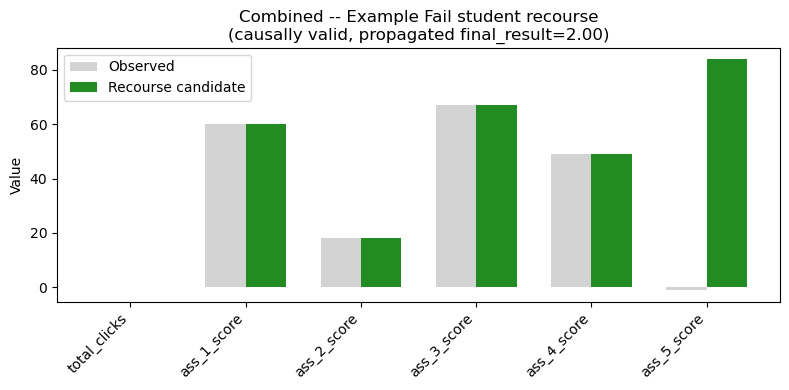

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_Fail_example_recourse.png
Changed features: ['ass_5_score']


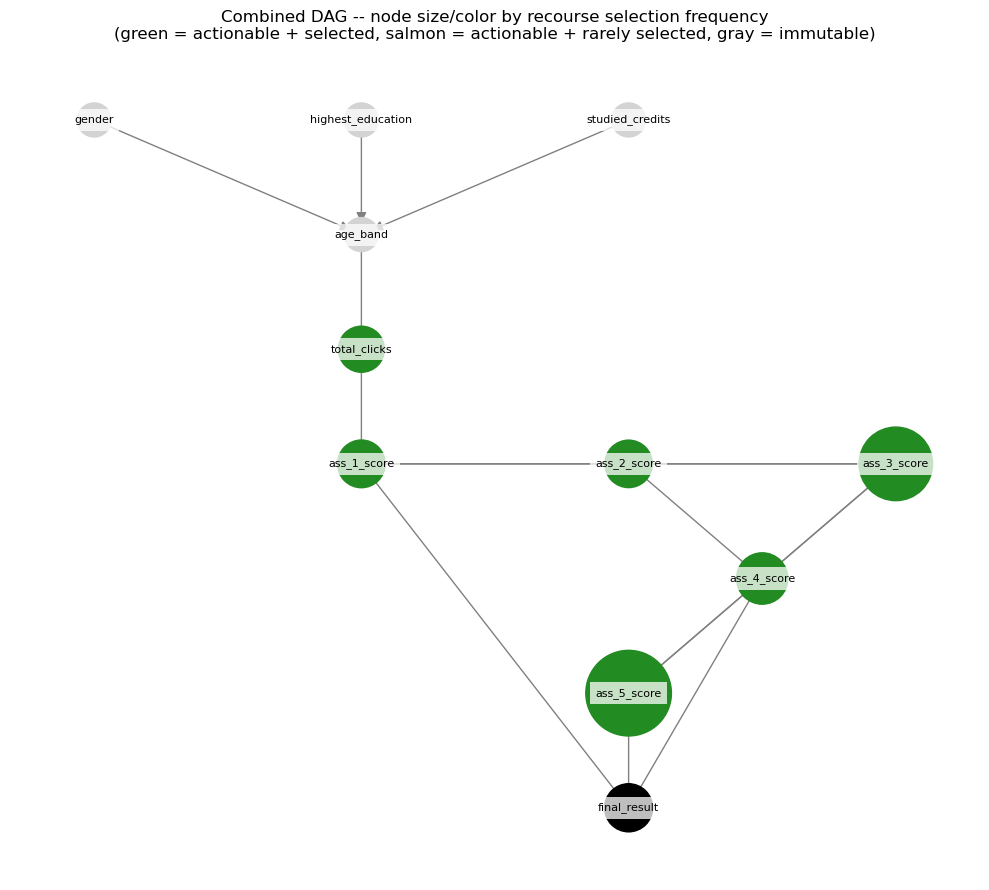

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_DAG_recourse_overlay.png


In [67]:
# ---- #1: pick one causally-valid example per cohort ----
def pick_example(candidates, verified, mode_col='causal_valid_prop_15'):
    valid_idx = verified[verified[mode_col]].index
    if len(valid_idx) == 0:
        print("No causally-valid candidate found under this mode.")
        return None
    pick = valid_idx[0]
    return candidates[pick], verified.loc[pick]

example_w, row_w = pick_example(candidates_wC, verified_wC)
example_f, row_f = pick_example(candidates_fC, verified_fC)

def plot_before_after(example, row, cohort_label, feat_cols):
    orig = example['orig_row'][feat_cols]
    cf = example['cf_row'][feat_cols]
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(feat_cols))
    width = 0.35
    ax.bar(x - width/2, orig.values, width, label='Observed', color='lightgray')
    ax.bar(x + width/2, cf.values, width, label='Recourse candidate', color='forestgreen')
    for i, f in enumerate(feat_cols):
        if f in example['changed_features']:
            ax.get_xticklabels()
    ax.set_xticks(x); ax.set_xticklabels(feat_cols, rotation=45, ha='right')
    ax.set_ylabel('Value')
    ax.set_title(f'Combined -- Example {cohort_label} student recourse\n'
                 f'(causally valid, propagated final_result={row["cf_final_result_propagated"]:.2f})')
    ax.legend(); plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_{cohort_label}_example_recourse.png")
    plt.savefig(path); plt.show()
    print("Saved:", path)
    print("Changed features:", example['changed_features'])

if example_w: plot_before_after(example_w, row_w, 'Withdrawn', feat_cols_combined)
if example_f: plot_before_after(example_f, row_f, 'Fail', feat_cols_combined)

# ---- #3: DAG with recourse-selection overlay ----
freq_combined_w = feature_change_freq(candidates_wC, feat_cols_combined)
freq_combined_f = feature_change_freq(candidates_fC, feat_cols_combined)
total_freq = (freq_combined_w + freq_combined_f).fillna(0)
max_freq = total_freq.max()

pos_combined = {
    'gender': (0, 4), 'highest_education': (1, 4), 'studied_credits': (2, 4),
    'age_band': (1, 3), 'total_clicks': (1, 2),
    'ass_1_score': (1, 1), 'ass_2_score': (2, 1), 'ass_3_score': (3, 1),
    'ass_4_score': (2.5, 0), 'ass_5_score': (2, -1),
    'final_result': (2, -2),
}

fig, ax = plt.subplots(figsize=(10, 9))
edges_combined_plot = [
    ('gender', 'age_band'), ('highest_education', 'age_band'), ('studied_credits', 'age_band'),
    ('age_band', 'total_clicks'), ('total_clicks', 'ass_1_score'),
    ('ass_1_score', 'ass_2_score'), ('ass_1_score', 'ass_3_score'), ('ass_1_score', 'final_result'),
    ('ass_2_score', 'ass_3_score'), ('ass_2_score', 'ass_4_score'),
    ('ass_3_score', 'ass_4_score'), ('ass_3_score', 'ass_5_score'),
    ('ass_4_score', 'ass_5_score'), ('ass_4_score', 'final_result'),
    ('ass_5_score', 'final_result'),
]
G_plot = nx.DiGraph(edges_combined_plot)

nx.draw_networkx_edges(G_plot, pos_combined, ax=ax, edge_color='gray', arrows=True, arrowsize=15)

node_colors = []
node_sizes = []
for n in G_plot.nodes():
    freq = total_freq.get(n, 0)
    if n == 'final_result':
        node_colors.append('black'); node_sizes.append(1200)
    elif freq > 0:
        node_colors.append('forestgreen'); node_sizes.append(800 + 3000 * (freq / max_freq))
    elif n in feat_cols_combined:
        node_colors.append('lightsalmon'); node_sizes.append(800)  # actionable but rarely selected
    else:
        node_colors.append('lightgray'); node_sizes.append(600)  # immutable

nx.draw_networkx_nodes(G_plot, pos_combined, ax=ax, node_color=node_colors, node_size=node_sizes)
nx.draw_networkx_labels(G_plot, pos_combined, ax=ax, font_size=8,
                         bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))

ax.set_title("Combined DAG -- node size/color by recourse selection frequency\n"
             "(green = actionable + selected, salmon = actionable + rarely selected, gray = immutable)")
ax.axis('off')
plt.tight_layout()
path = os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_DAG_recourse_overlay.png")
plt.savefig(path, dpi=150); plt.show()
print("Saved:", path)

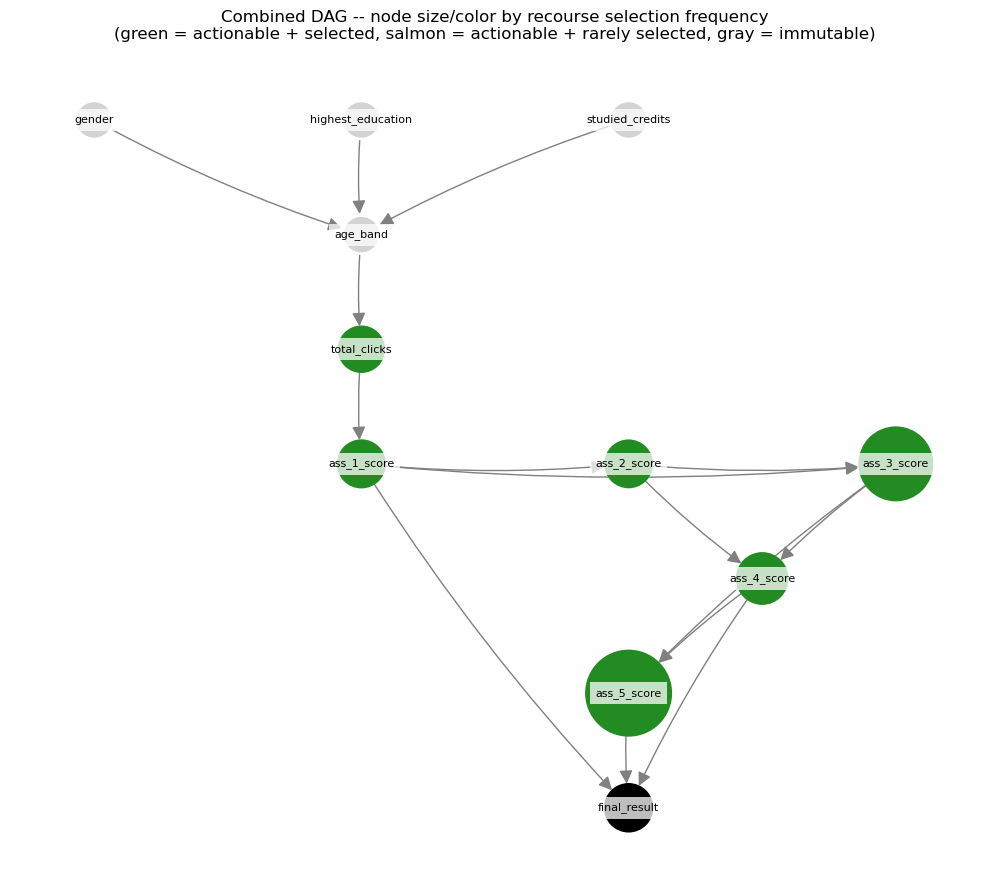

Saved: C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\AAA\AAA_RQ4_Combined_DAG_recourse_overlay.png
ass_5_score     538
ass_3_score     360
ass_4_score     102
ass_1_score      68
ass_2_score      66
total_clicks     54
dtype: int64


In [69]:
fig, ax = plt.subplots(figsize=(10, 9))

nx.draw_networkx_edges(
    G_plot, pos_combined, ax=ax, edge_color='gray',
    arrows=True, arrowsize=20, arrowstyle='-|>',
    connectionstyle='arc3,rad=0.05',
    node_size=[800 + 3000 * (total_freq.get(n, 0) / max_freq) if total_freq.get(n, 0) > 0
               else (1200 if n == 'final_result' else 800) for n in G_plot.nodes()],
    min_source_margin=15, min_target_margin=15
)

nx.draw_networkx_nodes(G_plot, pos_combined, ax=ax, node_color=node_colors, node_size=node_sizes)
nx.draw_networkx_labels(G_plot, pos_combined, ax=ax, font_size=8,
                         bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))

ax.set_title("Combined DAG -- node size/color by recourse selection frequency\n"
             "(green = actionable + selected, salmon = actionable + rarely selected, gray = immutable)")
ax.axis('off')
plt.tight_layout()
path = os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_DAG_recourse_overlay.png")
plt.savefig(path, dpi=150); plt.show()
print("Saved:", path)

# print the actual frequencies behind the sizing, so we can confirm the chart reads correctly
print(total_freq.sort_values(ascending=False))

# combined DAG shift-to-Success counterfactuals.

In [74]:
withdrawn_combined = get_cohort(df_combined, 0)
fail_combined = get_cohort(df_combined, 1)
success_combined = get_cohort(df_combined, [2, 3])

print("Combined -- Withdrawn:", len(withdrawn_combined), "| Fail:", len(fail_combined), "| Success:", len(success_combined))

Combined -- Withdrawn: 126 | Fail: 91 | Success: 531


In [76]:
cf_results_combined = []

nodes_to_shift = ['total_clicks', 'ass_1_score', 'ass_2_score', 'ass_4_score']

for node in nodes_to_shift:
    target_val = success_combined[node].median()
    for cohort_name, cohort_df in [('Withdrawn', withdrawn_combined), ('Fail', fail_combined)]:
        # style 1: raise to Success median, never lower
        cf_median = run_counterfactual(
            scm_combined, cohort_df,
            {node: lambda x, t=target_val: np.maximum(x, t)}
        )
        s = summarize_counterfactual(cf_median, f"{node}_to_success_median")
        s['node'] = node; s['cohort'] = cohort_name
        cf_results_combined.append(s)

        # style 2: step nudge -- +1 bin for total_clicks, +10 points for assessments
        if node == 'total_clicks':
            cf_step = run_counterfactual(scm_combined, cohort_df,
                {node: lambda x: np.minimum(x + 1, 3)})
        else:
            cf_step = run_counterfactual(scm_combined, cohort_df,
                {node: lambda x: np.clip(np.maximum(x, 0) + 10, 0, 100)})
        s2 = summarize_counterfactual(cf_step, f"{node}_step")
        s2['node'] = node; s2['cohort'] = cohort_name
        cf_results_combined.append(s2)

cf_summary_combined = pd.DataFrame(cf_results_combined)
print(cf_summary_combined)
cf_summary_combined.to_csv(os.path.join(OUTPUT_DIR, f"{MODULE}_RQ4_Combined_cf_summary.csv"), index=False)

                      intervention    n  mean_shift  median_shift  \
0   total_clicks_to_success_median  126    0.507937           1.0   
1                total_clicks_step  126    0.484127           0.0   
2   total_clicks_to_success_median   91    0.527473           1.0   
3                total_clicks_step   91    0.538462           1.0   
4    ass_1_score_to_success_median  126    0.753968           0.0   
5                 ass_1_score_step  126    0.571429           1.0   
6    ass_1_score_to_success_median   91    0.582418           0.0   
7                 ass_1_score_step   91    0.428571           0.0   
8    ass_2_score_to_success_median  126    0.928571           1.0   
9                 ass_2_score_step  126    0.738095           1.0   
10   ass_2_score_to_success_median   91    0.692308           1.0   
11                ass_2_score_step   91    0.494505           0.0   
12   ass_4_score_to_success_median  126    1.785714           2.0   
13                ass_4_score_step